# EDA: Training dataset dự đoán giá cà phê Đắk Lắk

Notebook này khám phá trực tiếp `data/features/training_dataset.csv`: chất lượng dữ liệu, diễn biến giá, feature thời tiết/lịch sử và target `next_day_price`. EDA chỉ đọc dữ liệu, không thay đổi file nguồn.

Nếu chưa có dataset, chạy `python src/pipeline.py` từ thư mục gốc của project.

In [3]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / "data/features/training_dataset.csv").exists():
    PROJECT_ROOT = Path.cwd().parent
DATA_PATH = PROJECT_ROOT / "data/features/training_dataset.csv"
if not DATA_PATH.exists():
    raise FileNotFoundError("Chưa có training_dataset.csv. Hãy chạy python src/pipeline.py từ thư mục project.")

df = pd.read_csv(DATA_PATH, parse_dates=["date"]).sort_values("date").reset_index(drop=True)
price_col = "coffee_price"
price_col_30 = "price_lag_30"
price_col_7 = "price_lag_7"
price_col_14 = "price_lag_14"
target_col = "next_day_price"
weather_cols = [
    "temperature_2m_mean", "temperature_2m_max", "temperature_2m_min",
    "precipitation_sum", "rain_sum", "precipitation_hours",
    "relative_humidity_2m_mean", "soil_moisture_0_to_7cm",
    "soil_moisture_7_to_28cm", "shortwave_radiation_sum",
]
print(f"Dataset: {len(df):,} rows x {len(df.columns)} columns")
print(f"Period: {df.date.min().date()} to {df.date.max().date()}")
print(f"Target: {target_col} (giá cà phê ngày kế tiếp)")
display(df.head())

Dataset: 863 rows x 35 columns
Period: 2024-05-18 to 2026-09-27
Target: next_day_price (giá cà phê ngày kế tiếp)


,date,coffee_price,temperature_2m_max,temperature_2m_min,temperature_2m_mean,precipitation_sum,rain_sum,precipitation_hours,relative_humidity_2m_mean,soil_moisture_0_to_7cm,...,temperature_mean_7d,temperature_mean_30d,humidity_mean_7d,humidity_mean_30d,day_of_week,day_of_month,month,quarter,next_day_price,date_gap_days
0,2024-05-18,103900,31.8,24.0,26.6,16.3,16.3,7.0,84,0.459,...,29.071429,29.476667,67.142857,63.800000,5,18,5,2,103900.0,1.0
1,2024-05-19,103900,29.0,24.4,26.1,3.0,3.0,7.0,86,0.473,...,28.600000,29.386667,70.571429,64.600000,6,19,5,2,104000.0,1.0
2,2024-05-20,104000,31.5,24.2,27.0,3.9,3.9,4.0,79,0.461,...,28.014286,29.273333,74.142857,65.433333,0,20,5,2,105600.0,1.0
3,2024-05-21,105600,27.3,24.3,25.7,1.7,1.7,9.0,85,0.445,...,27.542857,29.200000,77.000000,66.000000,1,21,5,2,110000.0,1.0
4,2024-05-22,110000,32.3,24.0,27.0,7.4,7.4,9.0,80,0.417,...,27.057143,29.070000,79.714286,66.766667,2,22,5,2,117000.0,1.0


## 1. Chất lượng và tổng quan dữ liệu

Kiểm tra ngày trùng, khoảng trống ngày, missing values và thống kê mô tả trước khi đọc biểu đồ. Những giá trị bất thường sẽ được đánh dấu để kiểm tra, không tự động xóa.

In [4]:
quality = pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "missing_count": df.isna().sum(),
    "missing_percent": (df.isna().mean() * 100).round(2),
    "unique_values": df.nunique(dropna=True),
})
date_gaps = df.date.diff().dt.days
expected_target = df[price_col].shift(-1)
target_mismatches = df[target_col].iloc[:-1].ne(expected_target.iloc[:-1]).sum()
print("Duplicate dates:", int(df.date.duplicated().sum()))
print("Missing calendar days:", int(date_gaps.gt(1).sum()))
print("Rows with any missing values:", int(df.isna().any(axis=1).sum()))
print("Rows where target differs from next row's coffee_price:", int(target_mismatches))
print("Non-daily date_gap_days rows:", int(df["date_gap_days"].ne(1).sum()))
display(quality)


Duplicate dates: 0
Missing calendar days: 0
Rows with any missing values: 0
Rows where target differs from next row's coffee_price: 0
Non-daily date_gap_days rows: 0


,dtype,missing_count,missing_percent,unique_values
date,datetime64[us],0,0.0,863
coffee_price,int64,0,0.0,289
temperature_2m_max,float64,0,0.0,135
temperature_2m_min,float64,0,0.0,93
temperature_2m_mean,float64,0,0.0,107
precipitation_sum,float64,0,0.0,221
rain_sum,float64,0,0.0,221
precipitation_hours,float64,0,0.0,25
relative_humidity_2m_mean,int64,0,0.0,54
soil_moisture_0_to_7cm,float64,0,0.0,274


## 2. Giá theo thời gian và xu hướng

Đường giá thể hiện biến động hàng ngày; rolling mean 7/30 ngày làm mượt nhiễu ngắn hạn để quan sát trend. Đây chỉ là phép mô tả, không phải feature dùng để dự đoán ở tương lai.

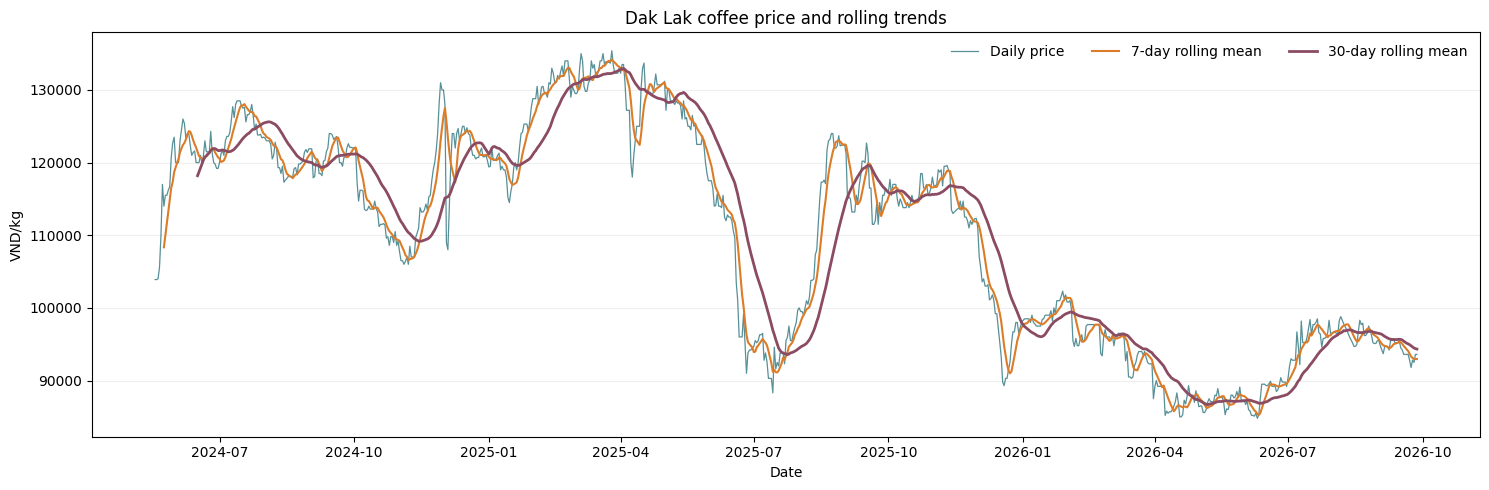

In [5]:
fig, ax = plt.subplots(figsize=(15, 5))
ax.plot(df.date, df[price_col], color="#1f6b75", linewidth=0.9, alpha=0.75, label="Daily price")
ax.plot(df.date, df[price_col].rolling(7).mean(), color="#dc7c28", linewidth=1.5, label="7-day rolling mean")
ax.plot(df.date, df[price_col].rolling(30).mean(), color="#8b4b62", linewidth=2, label="30-day rolling mean")
ax.set(title="Dak Lak coffee price and rolling trends", xlabel="Date", ylabel="VND/kg")
ax.grid(axis="y", alpha=0.2)
ax.legend(frameon=False, ncol=3)
plt.tight_layout()
plt.show()

## 3. Phân phối và outlier review

Histogram cho biết phân phối giá; boxplot và quy tắc IQR giúp khoanh vùng điểm cực đoan. Giá cà phê có thể có cú sốc thị trường thật, vì vậy outlier phải được đối chiếu nguồn trước khi quyết định xử lý.

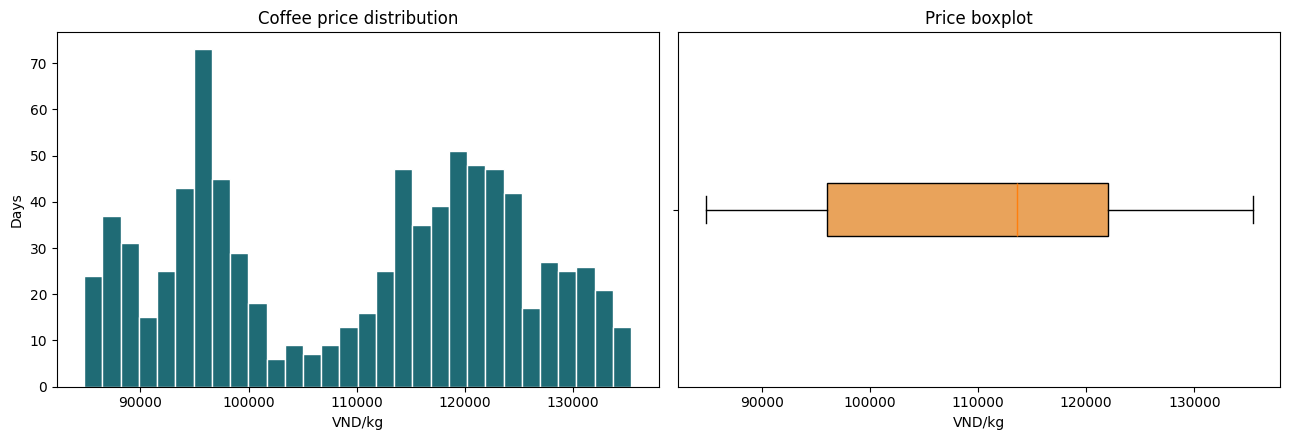

IQR fences: 57,000 to 161,000 VND/kg
Flagged points: 0; these are flagged for review, not removed.


,date,coffee_price


In [6]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].hist(df[price_col], bins=30, color="#1f6b75", edgecolor="white")
axes[0].set(title="Coffee price distribution", xlabel="VND/kg", ylabel="Days")
axes[1].boxplot(df[price_col], orientation="horizontal", patch_artist=True,
                boxprops={"facecolor": "#e9a35b"})
axes[1].set(title="Price boxplot", xlabel="VND/kg", yticklabels=[])
plt.tight_layout()
plt.show()

q1, q3 = df[price_col].quantile([0.25, 0.75])
iqr = q3 - q1
low_fence, high_fence = q1 - 1.5 * iqr, q3 + 1.5 * iqr
outliers = df.loc[(df[price_col] < low_fence) | (df[price_col] > high_fence), ["date", price_col]].copy()
print(f"IQR fences: {low_fence:,.0f} to {high_fence:,.0f} VND/kg")
print(f"Flagged points: {len(outliers)}; these are flagged for review, not removed.")
display(outliers.head(20))

## 4. Mùa vụ theo tháng và năm

biểu đồ theo năm cho thấy thay đổi mức giá dài hạn. Dữ liệu mới có khoảng vài năm nên mùa vụ chỉ là dấu hiệu ban đầu, chưa đủ để khẳng định chu kỳ ổn định.

In [7]:
df["year"] = df.date.dt.year
yearly_price = df.groupby("year")[price_col].agg(["mean", "median", "min", "max", "count"])
display(yearly_price.round(1))


,mean,median,min,max,count
year,,,,,
2024,119164.9,120600.0,103900,131000,228
2025,116375.1,117300.0,88300,135400,365
2026,93163.3,94550.0,84800,102300,270


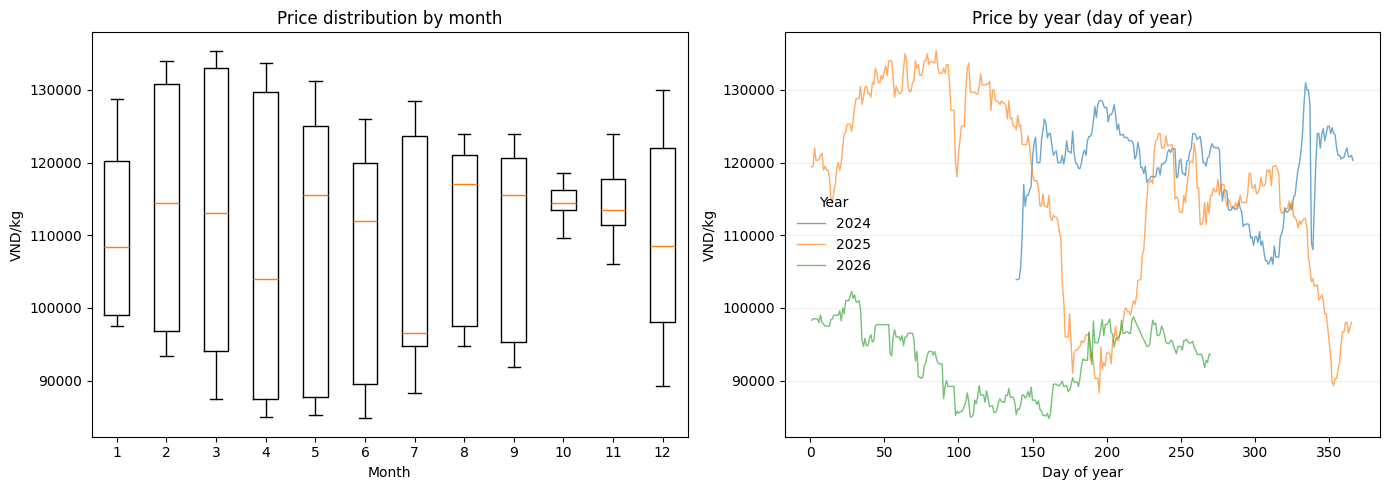

In [8]:

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
month_data = [df.loc[df.month == month, price_col].to_numpy() for month in range(1, 13)]
axes[0].boxplot(month_data, tick_labels=[str(month) for month in range(1, 13)], showfliers=False)
axes[0].set(title="Price distribution by month", xlabel="Month", ylabel="VND/kg")
for year, group in df.groupby("year"):
    axes[1].plot(group.date.dt.dayofyear, group[price_col], alpha=0.65, linewidth=1, label=str(year))
axes[1].set(title="Price by year (day of year)", xlabel="Day of year", ylabel="VND/kg")
axes[1].legend(title="Year", frameon=False)
axes[1].grid(axis="y", alpha=0.2)
plt.tight_layout()
plt.show()


## 5. Độ biến động theo thời gian

Thay đổi giá tuyệt đối cho biết các cú tăng/giảm từng ngày; rolling standard deviation 30 ngày cho biết mức biến động nền trong một khoảng dài hơn.

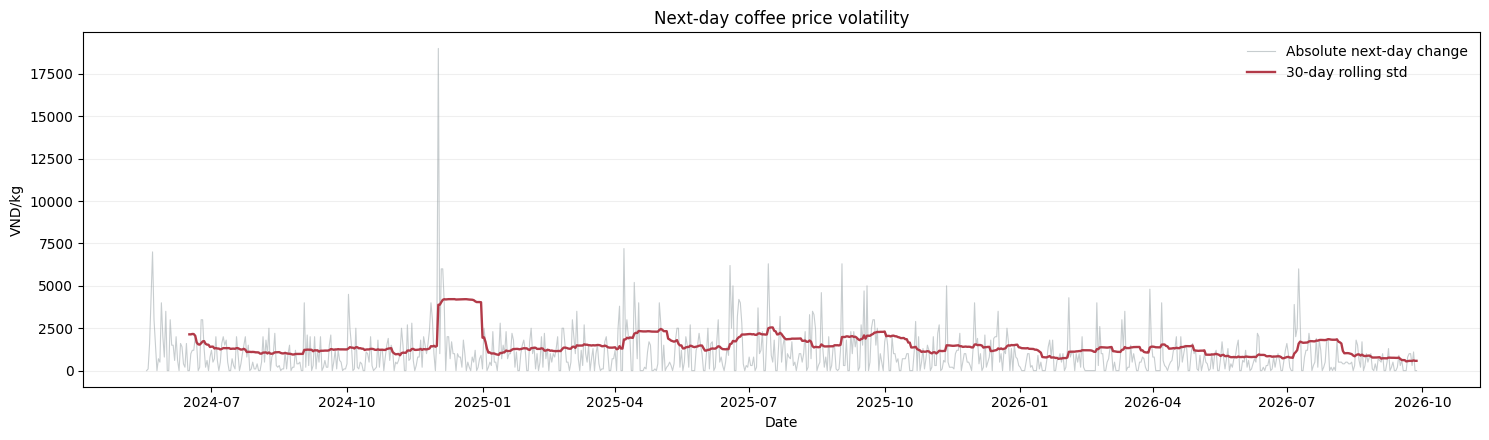

,date,coffee_price,next_day_price,daily_change,absolute_change
198,2024-12-02,128000,109000.0,-19000.0,19000.0
324,2025-04-07,127200,120000.0,-7200.0,7200.0
4,2024-05-22,110000,117000.0,7000.0,7000.0
422,2025-07-14,88300,94600.0,6300.0,6300.0
472,2025-09-02,121300,115000.0,-6300.0,6300.0
396,2025-06-18,109700,103500.0,-6200.0,6200.0
200,2024-12-04,108000,114000.0,6000.0,6000.0
201,2024-12-05,114000,120000.0,6000.0,6000.0
782,2026-07-09,92200,98200.0,6000.0,6000.0
331,2025-04-14,125000,130200.0,5200.0,5200.0


In [9]:
df["daily_change"] = df[target_col] - df[price_col]
df["rolling_volatility_30d"] = df["daily_change"].rolling(30).std()
fig, ax = plt.subplots(figsize=(15, 4.5))
ax.plot(df.date, df.daily_change.abs(), color="#9aa4a8", linewidth=0.8, alpha=0.55, label="Absolute next-day change")
ax.plot(df.date, df.rolling_volatility_30d, color="#b23a48", linewidth=1.7, label="30-day rolling std")
ax.set(title="Next-day coffee price volatility", xlabel="Date", ylabel="VND/kg")
ax.legend(frameon=False)
ax.grid(axis="y", alpha=0.2)
plt.tight_layout()
plt.show()
display(df.loc[df.daily_change.abs().nlargest(10).index, ["date", price_col, target_col, "daily_change"]].assign(
    absolute_change=lambda x: x.daily_change.abs()
).sort_values("absolute_change", ascending=False))

## 6. tương quan với target

Kiểm tra missingness trên chính training dataset. Pearson correlation được dùng để xem quan hệ tuyến tính giữa feature tại ngày `T` và target `next_day_price` tại `T+1`; tương quan không đồng nghĩa quan hệ nhân quả và không thay thế validation theo thời gian.

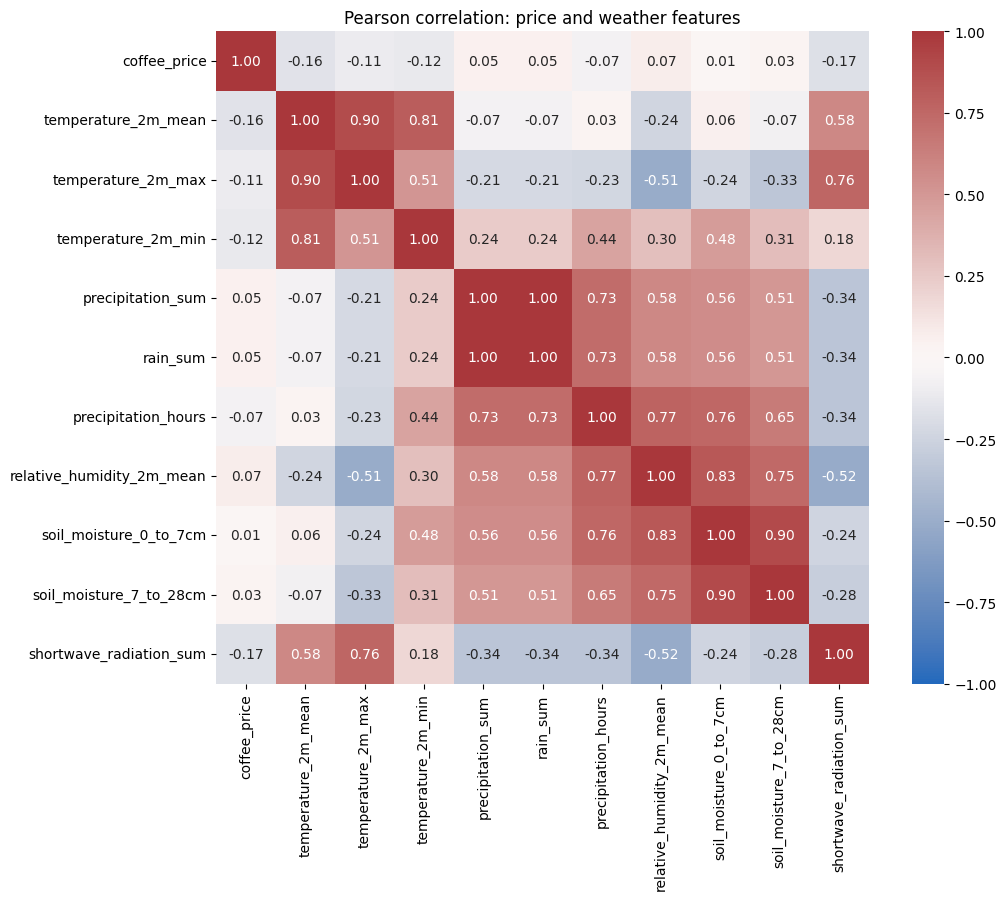

,pearson_r_with_price
shortwave_radiation_sum,-0.172
temperature_2m_mean,-0.156
temperature_2m_min,-0.123
temperature_2m_max,-0.106
relative_humidity_2m_mean,0.071
precipitation_hours,-0.068
rain_sum,0.050
precipitation_sum,0.050
soil_moisture_7_to_28cm,0.034
soil_moisture_0_to_7cm,0.012


In [13]:

corr_cols = [price_col, *[col for col in weather_cols if col in source_data.columns]]
corr = source_data[corr_cols].corr(numeric_only=True)
fig, ax = plt.subplots(figsize=(11, 9))
sns.heatmap(corr, cmap="vlag", center=0, vmin=-1, vmax=1, annot=True, fmt=".2f", square=True, ax=ax)
ax.set_title("Pearson correlation: price and weather features")
plt.tight_layout()
plt.show()
price_correlations = corr[price_col].drop(price_col).sort_values(key=lambda values: values.abs(), ascending=False)
display(price_correlations.rename("pearson_r_with_price").to_frame().round(3))

,pearson_r_with_current_price
price_mean_7,0.981
price_lag_7,0.954
price_lag_14,0.908
price_lag_30,0.774
shortwave_radiation_sum,-0.172
temperature_2m_mean,-0.156
temperature_2m_min,-0.123
temperature_2m_max,-0.106
relative_humidity_2m_mean,0.071
precipitation_hours,-0.068


,pearson_r_with_next_day_price
coffee_price,0.994
price_lag_1,0.987
price_lag_2,0.980
price_mean_7,0.975
price_lag_3,0.974
price_mean_14,0.959
price_lag_7,0.948
price_mean_30,0.918
price_lag_14,0.901
price_lag_30,0.768


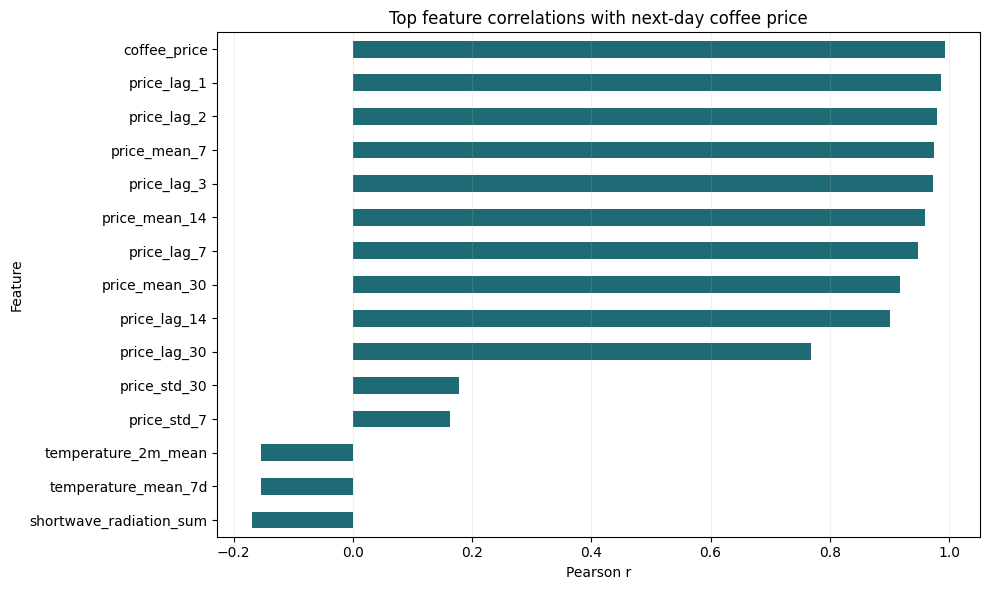

In [15]:

price_correlations = corr[price_col].drop(price_col).sort_values(key=lambda values: values.abs(), ascending=False)
display(price_correlations.rename("pearson_r_with_current_price").to_frame().round(3))

numeric_data = source_data.select_dtypes(include="number")
target_correlations = numeric_data.corr()[target_col].drop(
    labels=[target_col, "date_gap_days"], errors="ignore"
).sort_values(key=lambda values: values.abs(), ascending=False)
top_target_correlations = target_correlations.head(15).sort_values()
display(target_correlations.rename("pearson_r_with_next_day_price").to_frame().round(3))
fig, ax = plt.subplots(figsize=(10, 6))
top_target_correlations.plot(kind="barh", ax=ax, color="#1f6b75")
ax.set(title="Top feature correlations with next-day coffee price", xlabel="Pearson r", ylabel="Feature")
ax.grid(axis="x", alpha=0.2)
plt.tight_layout()
plt.show()
